In [1]:
from transformers import AutoTokenizer
import torch
import os
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from scipy import stats
from tqdm.notebook import tqdm
import seaborn as sns
import sys
sys.path.append('..')
from utils import model_to_path_dict

In [2]:
save_dir = '../../generated'
model_name = 'Llama3-8b-instruct'
results_save_dir = os.path.join(save_dir,model_to_path_dict[model_name]['save_dir_name'],'test_lm_ce_diff')
with open(os.path.join(results_save_dir,'%s_generated.pkl'%model_name),'rb') as f:
    generated_dict = pickle.load(f)
generated_token_len = []
generated_ce = []
for num_generated_tokens in tqdm(generated_dict.keys()): # keys are max generated tokens. actual generations could be shorter
#     if num_generated_tokens > 500:
#         print(generated_dict[num_generated_tokens]['generated_txt'])
    this_generated_ce = generated_dict[num_generated_tokens]['ce']
    this_generated_ce = [torch.sum(ce).numpy() for ce in this_generated_ce]
    this_generated_token_len = [ce.shape[0] for ce in generated_dict[num_generated_tokens]['ce']]
    generated_ce.extend(this_generated_ce)
    generated_token_len.extend(this_generated_token_len)
generated_ce = np.array(generated_ce).astype(float)
results_df = pd.DataFrame({'token_len':generated_token_len,model_name:generated_ce})

  0%|          | 0/20 [00:00<?, ?it/s]

In [4]:
inference_models = ['gpt2','gpt2-medium','gpt2-large','gpt2-xl','meta-llama/Llama-3.2-1B','meta-llama/Llama-3.2-3B']
for inf_model in inference_models:
    if '/' in inf_model:
        save_name = inf_model.split('/')[1]
    else:
        save_name = inf_model
    with open(os.path.join(results_save_dir,'%s_inference.pkl'%save_name),'rb') as f:
        inference_dict = pickle.load(f)
    inference_ce = []
    for num_generated_tokens in inference_dict.keys():
        this_inference_ce = inference_dict[num_generated_tokens]
        this_inference_ce = [torch.sum(ce).numpy() for ce in this_inference_ce]
        inference_ce.extend(this_inference_ce)
    results_df[save_name] = np.array(inference_ce).astype(float)

Let $X$ be the text and $Xi$ be a token in the story. $P(X)$ be the probability distribution from the generating model, $Q(X)$ be the distribution for the evaluating model. <br/><br/>
$D_{KL}(P||Q) = -\sum_{x\in X} P(X)logQ(X)-(-\sum_{x\in X}P(X)logP(X))$ <br/><br/>
When calculating surprisal, we treat $P(x_i) = 1$ if $x_i$ is the correct next token (let's call it x'), else 0. <br/><br/>

Thus surprisal or cross entropy of $X$ under the generating distribution is $-\sum_{i=1}^{n}logP(x_i') = -P(x')logP(x') = -\sum_xP(X)logP(X)$, because $P(x_i) = 1$ if $x_i$ is the correct next token (let's call it x'), else 0 <br/><br/>
Cross entropy of $X$ under the evaluating distribution is $H(X^Q) = -logQ(x') = -Q(x')logQ(x') =-P(x')logQ(x') = -\sum_xP(X)logQ(X)$ because $P(x_i) = Q(x_i) = 1$ for $x_i = x'$ else $P(x_i) = Q(x_i) = 0$

Thus $D_{KL}(P||Q) = -P(x')logQ(x')-(-P(x')logP(x'))$, the difference between cross entropy under the evaluating model and the generating model

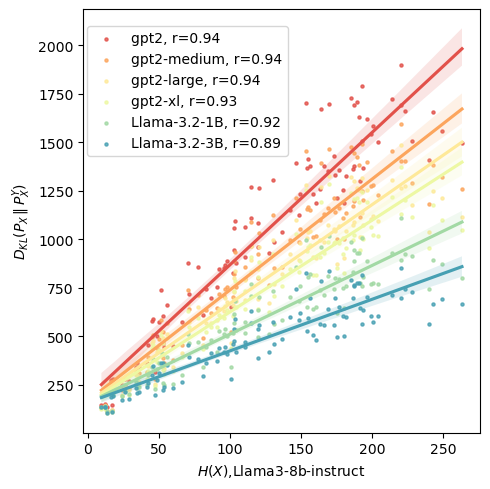

In [8]:
fig,ax = plt.subplots(figsize = (5,5))
colors = sns.color_palette("Spectral", len(inference_models))
for i,inf_model in enumerate(inference_models):
    if '/' in inf_model:
        save_name = inf_model.split('/')[1]
    else:
        save_name = inf_model
    ce_diff = results_df[save_name]-results_df['Llama3-8b-instruct']
    corr = np.corrcoef(results_df['Llama3-8b-instruct'],ce_diff)[0,1]
    #ax.scatter(results_df['Llama3-8b-instruct'],ce_diff,label = '%s, r=%.2f'%(save_name,corr),s=5)
    scatter = sns.regplot(
            x=results_df['Llama3-8b-instruct'],
            y=ce_diff,
            color=colors[i],
            ci=95,
            scatter_kws=dict(s=5),
           label = '%s, r=%.2f'%(save_name,corr),
           ax = ax)
ax.set_xlabel(r'$H(X)$,'+model_name)
ax.set_ylabel(r"$D_{KL}(P_{X}\,\|\,P_{X}^{Y})$")
plt.tight_layout()
fig.legend(bbox_to_anchor=(0.6,0.95))
fig.savefig(os.path.join(results_save_dir,'kl_assumption_check.pdf'),transparent = True)